In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
raw_data=pd.read_excel(r'C:\Users\Jose.Hurtado\Downloads\Export.xlsx')
raw_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 44446 entries, 0 to 44445
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Created  44446 non-null  str  
 1   Message  44446 non-null  str  
 2   Status   44446 non-null  str  
dtypes: str(3)
memory usage: 1.0 MB


In [3]:
aux=pd.DataFrame()
aux=raw_data
aux['Headers']='NaN'

for i in range(0,aux.shape[0]):
    aux.iloc[i,3]=aux.iloc[i,2][0:8]

aux['Headers'].value_counts()

Headers
0x252514    37481
0x252513     6807
0x252501       88
0x252511       70
Name: count, dtype: int64

In [4]:
raw_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 44446 entries, 0 to 44445
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Created  44446 non-null  str  
 1   Message  44446 non-null  str  
 2   Status   44446 non-null  str  
 3   Headers  44446 non-null  str  
dtypes: str(4)
memory usage: 1.4 MB


Odometer

In [5]:
unit_13=raw_data[raw_data['Status'].str.contains('0x252513')]
unit_14=raw_data[raw_data['Status'].str.contains('0x252514')]
unit_aux=pd.concat([unit_13,unit_14])
unit_aux['Odometer in meters']=0.0
odometer=[]
date=[]
raw=[]
unit=pd.DataFrame()

for i in range(0,unit_aux.shape[0]):
    odometer.append(int(unit_aux.iloc[i,2][96:104],16))
    date.append(unit_aux.iloc[i,2][106:118])
    raw.append(unit_aux.iloc[i,2])    

unit_aux['Odometer in meters']=odometer
unit_aux['Date']=date
unit_aux['Raw data']=raw

#print(unit_aux['Odometer in meters'])

unit=unit_aux.sort_values('Date',ascending=True)

print(unit.info())

<class 'pandas.DataFrame'>
Index: 44288 entries, 8973 to 44445
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Created             44288 non-null  str  
 1   Message             44288 non-null  str  
 2   Status              44288 non-null  str  
 3   Headers             44288 non-null  str  
 4   Odometer in meters  44288 non-null  int64
 5   Date                44288 non-null  str  
 6   Raw data            44288 non-null  str  
dtypes: int64(1), str(6)
memory usage: 2.7 MB
None


000101000104 -> 0 -> 42832552.0 -> 0x252514005926700869487064612889007800782D00000064CC00000000000041000000FFFFFFFFFFFFFFFFFFFF0380028D92A838000101000104331B5E456C6E97C281303CC10000012603722783FFFFFF000026FFFFFFFFFF
000101000104 -> 1 -> 42832552.0 -> 0x252514005926710869487064612889007800782D00000064CC00000000000041000000FFFFFFFFFFFFFFFFFFFF0380028D92A838000101000104331B5E456C6E97C281303CC10000012603722783FFFFFF000026FFFFFFFFFF
000101000104 -> 2 -> 42832552.0 -> 0x252514005926720869487064612889007800782D00000064CC00000000000041000000FFFFFFFFFFFFFFFFFFFF0380028D92A838000101000104331B5E456C6E97C281303CC10000012603722780FFFFFF000027FFFFFFFFFF
000101000104 -> 3 -> 42832552.0 -> 0x252514005926730869487064612889007800782D00000064CC00000000000041000000FFFFFFFFFFFFFFFFFFFF0380028D92A838000101000104331B5E456C6E97C281303CC10000012603722780FFFFFF000027FFFFFFFFFF
000101000105 -> 4 -> 42832552.0 -> 0x2525140059267D0869487064612889007800782D00000064CC00000000000041000000FFFFFFFFFFFFFFFFFFFF0380028D9

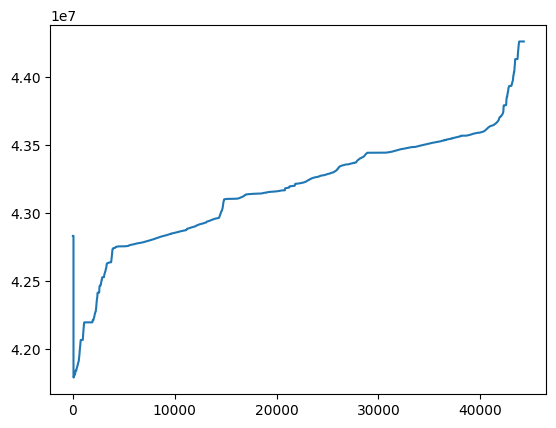

In [6]:
y_axis=[]
x_axis=[]
date=[]
raw_data_=[]

for i in range(0,unit.shape[0]):
    #print(float(fsq694_m_odometer.iloc[i,6][8:15]))
    y_axis.append(float(unit.iloc[i,4]))
    x_axis.append(i)
    date.append(unit.iloc[i,5])
    raw_data_.append(unit.iloc[i,6])

#print("Delta odometer: ",y_axis[170]-y_axis[133],'meters')

for i in range(0,len(odometer)):
    print(date[i],'->',x_axis[i],'->',y_axis[i],'->',raw_data_[i])

#print(odometer[len(odometer)-1]-odometer[0])
plt.plot(x_axis,y_axis)

Speed

In [7]:
unit_13=raw_data[raw_data['Status'].str.contains('0x252513')]
unit_14=raw_data[raw_data['Status'].str.contains('0x252514')]
unit_aux=pd.concat([unit_13,unit_14])
#unit_aux['Odometer in meters']=0.0
speed=[]
date=[]
raw=[]
unit_speed=pd.DataFrame()
unit=pd.DataFrame()

for i in range(0,unit_aux.shape[0]):
    try:
        lbs_ind=(bin(int(unit_aux.iloc[i,2][50:52],16) & 64))
        if lbs_ind=='0b1000000':
            speed.append(int(unit_aux.iloc[i,2][142:145]))  
            date.append(unit_aux.iloc[i,2][106:118])
            raw.append(unit_aux.iloc[i,2])
            #print(lbs_ind)

    except:
        pass    

unit_speed['Speed']=speed
unit_speed['Date']=date
unit_speed['Raw data']=raw

unit=unit_speed.sort_values('Date',ascending=True)

print(unit.info())

<class 'pandas.DataFrame'>
Index: 44129 entries, 12133 to 6802
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Speed     44129 non-null  int64
 1   Date      44129 non-null  str  
 2   Raw data  44129 non-null  str  
dtypes: int64(1), str(2)
memory usage: 1.3 MB
None


261101115538 -> 605 -> 58.0 -> 0x25251300591D210869487064612889007800782D000000225100000000000061000000FFFFFFFFFFFFFFFFFFFF00D5027FE2F86726110111553866F6744570F497C28BC839C10580002A03812815FFFFFF0000200000FFFFFF
261101122600 -> 624 -> 65.0 -> 0x25251300591D340869487064612889007800782D0000002C5000000000000061000000FFFFFFFFFFFFFFFFFFFF00D50280241968261101122600003868452ACA97C2CB9638C1065000A803812799FFFFFF0000200000FFFFFF
261101122659 -> 625 -> 57.0 -> 0x25251300591D350869487064612889007800782D0000003A5000000000000061000000FFFFFFFFFFFFFFFFFFFF00D5028027C86926110112265900086845D5C797C2E7B238C10570007803812795FFFFFF0000200000FFFFFF
261101122714 -> 626 -> 63.0 -> 0x25251300591D360869487064612889007800782D000000445000000000000061000000FFFFFFFFFFFFFFFFFFFF00D5028028BF6926110112271433E36745B8C697C2EFB338C10630004903812799FFFFFF0000200000FFFFFF
261101123040 -> 631 -> 58.0 -> 0x25251300591D3B0869487064612889007800782D00000000CF00000000000061000000FFFFFFFFFFFFFFFFFFFF0080028034FE68261101123040663

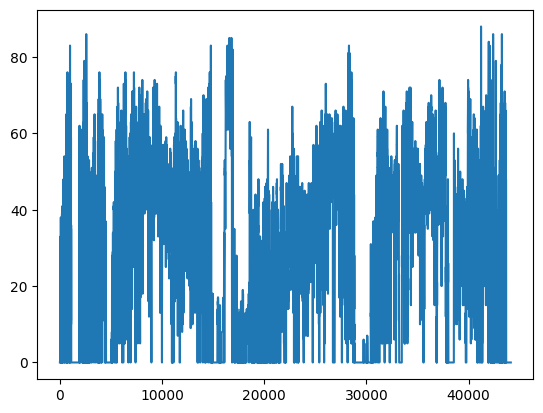

In [8]:
y_axis=[]
x_axis=[]
date=[]
raw_data_=[]

for i in range(0,unit.shape[0]):
    #print(float(fsq694_m_odometer.iloc[i,6][8:15]))
    y_axis.append(float(unit.iloc[i,0]))
    x_axis.append(i)
    date.append(unit.iloc[i,1])
    raw_data_.append(unit.iloc[i,2])
    #print(raw_data_[i])

for i in range(0,len(speed)):
    if (y_axis[i]>55):
        print(date[i],'->',x_axis[i],'->',y_axis[i],'->',raw_data_[i])

plt.plot(x_axis,y_axis)

Satellites

In [9]:
unit_13=raw_data[raw_data['Status'].str.contains('0x252513')]
unit_14=raw_data[raw_data['Status'].str.contains('0x252514')]
unit_aux=pd.concat([unit_13,unit_14])
satellite_number=[]
satellite_connection_indicator=[]
date=[]
raw=[]
num_events=0

for i in range(0,unit_aux.shape[0]):
    satellite_number.append(int(unit_aux.iloc[i,2][50:52],16) & 31)
    satellite_connection_indicator.append(int(unit_aux.iloc[i,2][50:52],16) & 128)
    date.append(unit_aux.iloc[i,2][106:118])
    raw.append(unit_aux.iloc[i,2])    

unit_aux['Satellites']=satellite_number
unit_aux['Satellite_connection_indicator']=satellite_connection_indicator
unit_aux['Raw data']=raw
unit_aux['date']=date

unit=unit_aux.sort_values('date',ascending=True)
unit.info()

for i in range(0,unit.shape[0]):
    if unit.iloc[i,4]<1:
        num_events=num_events+1
        print(unit.iloc[i,0], '->',unit.iloc[i,4],'->',unit.iloc[i,5],'->',unit.iloc[i,6])

print("Eventos históricos: ",num_events)

<class 'pandas.DataFrame'>
Index: 44288 entries, 8973 to 44445
Data columns (total 8 columns):
 #   Column                          Non-Null Count  Dtype
---  ------                          --------------  -----
 0   Created                         44288 non-null  str  
 1   Message                         44288 non-null  str  
 2   Status                          44288 non-null  str  
 3   Headers                         44288 non-null  str  
 4   Satellites                      44288 non-null  int64
 5   Satellite_connection_indicator  44288 non-null  int64
 6   Raw data                        44288 non-null  str  
 7   date                            44288 non-null  str  
dtypes: int64(2), str(6)
memory usage: 3.0 MB
2026-11-01 09:14:47.159 -> 0 -> 0 -> 0x25251300591C4C0869487064612889007800782D000000250000000000000061000000FFFFFFFFFFFFFFFFFFFF00D5027EC5E16726110109150082CC000A0581DD673715000E014C000003812777FFFFFF00001FFFFFFFFFFF
2026-11-01 09:42:46.604 -> 0 -> 0 -> 0x25251300591C

In/Outs

15      14                 13      12      11      10      09      08       07 06 05 04 03 02 01 00
Power   Ignition/Input0    Input1  Input2  Input3  Input4  Input5  Input0

15=0, Connected
15=1. Disconnected

In [10]:
unit_13=raw_data[raw_data['Status'].str.contains('0x252513')]
unit_14=raw_data[raw_data['Status'].str.contains('0x252514')]
unit_aux=pd.concat([unit_13,unit_14])
unit_aux.info()
aux_cad=[]
aux_date=[]
aux_raw_data=[]
aux_input_number=[]
in_outs=[]

#unit_aux.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\sym\concatenated.csv')

for i in range(0,unit_aux.shape[0]):
    long_cad=len(unit_aux.iloc[i,2])
    if ((long_cad>48) & (long_cad<204)):
        aux_cad.append(unit_aux.iloc[i,2])   

for i in range(0,len(aux_cad)):
    aux_value=aux_cad[i][64:68]
    aux_date.append(aux_cad[i][106:118])
    aux_raw_data.append(aux_cad[i])
    in_outs.append(bin (int (aux_cad[i][64:68],16)))      

unit_=pd.DataFrame()
unit_['in and outs']=in_outs
unit_['date']=aux_date
unit_['raw data']=aux_raw_data

in_outs_df=unit_.sort_values('date',ascending=True)

#in_outs_df.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\sym\in_outs.csv')

<class 'pandas.DataFrame'>
Index: 44288 entries, 0 to 43987
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Created  44288 non-null  str  
 1   Message  44288 non-null  str  
 2   Status   44288 non-null  str  
 3   Headers  44288 non-null  str  
dtypes: str(4)
memory usage: 1.7 MB


Ignition

In [11]:
in_outs_df.info()

for i in range(0,in_outs_df.shape[0]):
    length=len(in_outs_df.iloc[i,0])
    if length>16:
        aux_ign=in_outs_df.iloc[i,0][2:3]
        if aux_ign=='1':
            print("Ignition On",in_outs_df.iloc[i,0])
        if aux_ign=='0':
            print("Ignition Off",in_outs_df.iloc[i,0])
    else:
        aux_ign=in_outs_df.iloc[i,0][2:3]
        if aux_ign=='1':
            print("Ignition On",in_outs_df.iloc[i,0])
        if aux_ign=='0':
            print("Ignition Off",in_outs_df.iloc[i,0])

<class 'pandas.DataFrame'>
Index: 44288 entries, 12137 to 6806
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   in and outs  44288 non-null  str  
 1   date         44288 non-null  str  
 2   raw data     44288 non-null  str  
dtypes: str(3)
memory usage: 1.4 MB
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition 

Power

In [12]:
ext_bat_13=raw_data[raw_data['Status'].str.contains('0x252513')]
ext_bat_14=raw_data[raw_data['Status'].str.contains('0x252514')]
ext_bat_vol=pd.concat([ext_bat_13,ext_bat_14])
ext_bat=[]
date_bat=[]
bat_df=pd.DataFrame()

ext_bat_vol.info()

for i in range(0,ext_bat_vol.shape[0]):
    val=(float(ext_bat_vol.iloc[i,2][154:158]))/100
    date_bat.append(ext_bat_vol.iloc[i,2][106:119])
    ext_bat.append(val)
#print(ext_bat)

for i in range(0,ext_bat_vol.shape[0]):
    if ext_bat[i]<3:
        bat_df['Date']=date_bat
        bat_df['int_bat']=ext_bat

print(bat_df)

<class 'pandas.DataFrame'>
Index: 44288 entries, 0 to 43987
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Created  44288 non-null  str  
 1   Message  44288 non-null  str  
 2   Status   44288 non-null  str  
 3   Headers  44288 non-null  str  
dtypes: str(4)
memory usage: 1.7 MB
Empty DataFrame
Columns: []
Index: []


Pánico

In [13]:
unit_13=raw_data[raw_data['Status'].str.contains('0x252513')]
unit_14=raw_data[raw_data['Status'].str.contains('0x252514')]
unit_aux=pd.concat([unit_13,unit_14])
unit_aux.info()
aux_cad=[]
aux_date=[]
aux_raw_data=[]
aux_input_number=[]

#unit_aux.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\sym\concatenated.csv')

for i in range(0,unit_aux.shape[0]):
    long_cad=len(unit_aux.iloc[i,2])
    if ((long_cad>48) & (long_cad<204)):
        aux_cad.append(unit_aux.iloc[i,2])   

for i in range(0,len(aux_cad)):
    aux_value=aux_cad[i][92:94]
    aux_date.append(aux_cad[i][106:118])
    #aux_raw_data.append(aux_cad[i])
    if aux_value=='03':
        print(aux_value, ' -> ',aux_date[i])    

print("len aux_cad: ",len(aux_cad))

<class 'pandas.DataFrame'>
Index: 44288 entries, 0 to 43987
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Created  44288 non-null  str  
 1   Message  44288 non-null  str  
 2   Status   44288 non-null  str  
 3   Headers  44288 non-null  str  
dtypes: str(4)
memory usage: 1.7 MB
03  ->  261104113155
03  ->  261104113157
03  ->  261104113159
03  ->  261104113200
03  ->  261104113200
03  ->  261104113201
03  ->  261104113202
03  ->  261104113204
03  ->  261104113205
03  ->  261104114759
03  ->  261104114805
03  ->  261104114809
03  ->  261104114810
03  ->  261104114814
03  ->  261104114814
03  ->  261104114816
03  ->  261104114817
03  ->  261104114820
03  ->  261104114822
03  ->  261104114824
03  ->  261104114826
03  ->  261104114827
03  ->  261104114844
03  ->  261104114847
03  ->  261104114848
03  ->  261104114850
03  ->  261104114852
03  ->  261104114854
03  ->  261104114855
03  ->  261104114857
03  ->  261104114858
03  -